In [1]:
import pickle
import matplotlib.pyplot as plt
import networkx as nx
import os

In [2]:
with open( f"{os.getcwd()}/graphs/instances.pkl", "rb" ) as f:
  dic = pickle.load( f )

In [3]:
with open( f"{os.getcwd()}/graphs/instances_simplified.pkl", "rb" ) as f:
  dic_simpli = pickle.load( f )

In [4]:
composite_numbers = []

for k,v in dic.items():
  # fig = plt.figure(figsize=(15, 15)) 
  p = k[0]
  q = k[1]
  # print( f"Primes: {p} and {q}" )

  literals = sum( [len(v2) for k,v2 in v["SAT"].items()] )

  G : nx.Graph = v["easyG"]

  n_nodes = G.number_of_nodes()
  n_edges = G.number_of_edges()

  composite_numbers.append( ( p*q, p, q, v['max_deg'], v['avg_deg'], v['n_vars'], v['n_clauses'], literals, n_nodes, n_edges ) )

  # print( v["simplified_SAT"] )
  # print( f"#Variables before: {v['old_vars']}") 
  # print( f"#Clauses before: {v['old_clauses']}" )
  # print( f"#Variables after: {v['n_vars']}" )
  # print( f"#Clauses after: {v['n_clauses']}" )
  # print( f"Time to SAT: {v['timeSAT']}" )
  # print( f"Max degree: {v['max_deg']}" )
  # print( f"Avg degree: {v['avg_deg']}" )
  # Throw away all singletons
  # G.remove_nodes_from( list(nx.isolates(G)) )

  # nx.draw( G, node_size=60 )
  # plt.show()

In [5]:
composite_numbers_simpli = []

for k,v in dic_simpli.items():
  # fig = plt.figure(figsize=(15, 15)) 
  p = k[0]
  q = k[1]
  # print( f"Primes: {p} and {q}" )

  literals = sum( [len(v2) for k,v2 in v["SAT"].items()] )

  G : nx.Graph = v["easyG"]

  n_nodes = G.number_of_nodes()
  n_edges = G.number_of_edges()

  composite_numbers_simpli.append( ( p*q, p, q, v['max_deg'], v['avg_deg'], v['n_vars'], v['n_clauses'], literals, n_nodes, n_edges ) )

Composite numbers legend: contains:

p*q, p, q, max_degree, avg_degree, number of variables, number of clauses, number of literals

In [6]:
sorted_info = sorted( composite_numbers, key=lambda x: x[0] )

sorted_info_simpli = sorted( composite_numbers_simpli, key=lambda x: x[0] )

In [7]:
N = [ x[0] for x in sorted_info ]

p_s = [ x[1] for x in sorted_info ]
q_s = [ x[2] for x in sorted_info ]

max_ = [ x[3] for x in sorted_info ]
avg_ = [ x[4] for x in sorted_info ]

var_num = [ x[5] for x in sorted_info ]
clauses_num = [ x[6] for x in sorted_info ]

literals_num = [ x[7] for x in sorted_info ]

num_nodes = [ x[8] for x in sorted_info ]
num_edges = [ x[9] for x in sorted_info ]

In [8]:
N_simpli = [ x[0] for x in sorted_info_simpli ]

max__simpli = [ x[3] for x in sorted_info_simpli ]
avg__simpli = [ x[4] for x in sorted_info_simpli ]

var_num_simpli = [ x[5] for x in sorted_info_simpli ]
clauses_num_simpli = [ x[6] for x in sorted_info_simpli ]

literals_num_simpli = [ x[7] for x in sorted_info_simpli ]

num_nodes_simpli = [ x[8] for x in sorted_info_simpli ]
num_edges_simpli = [ x[9] for x in sorted_info_simpli ]

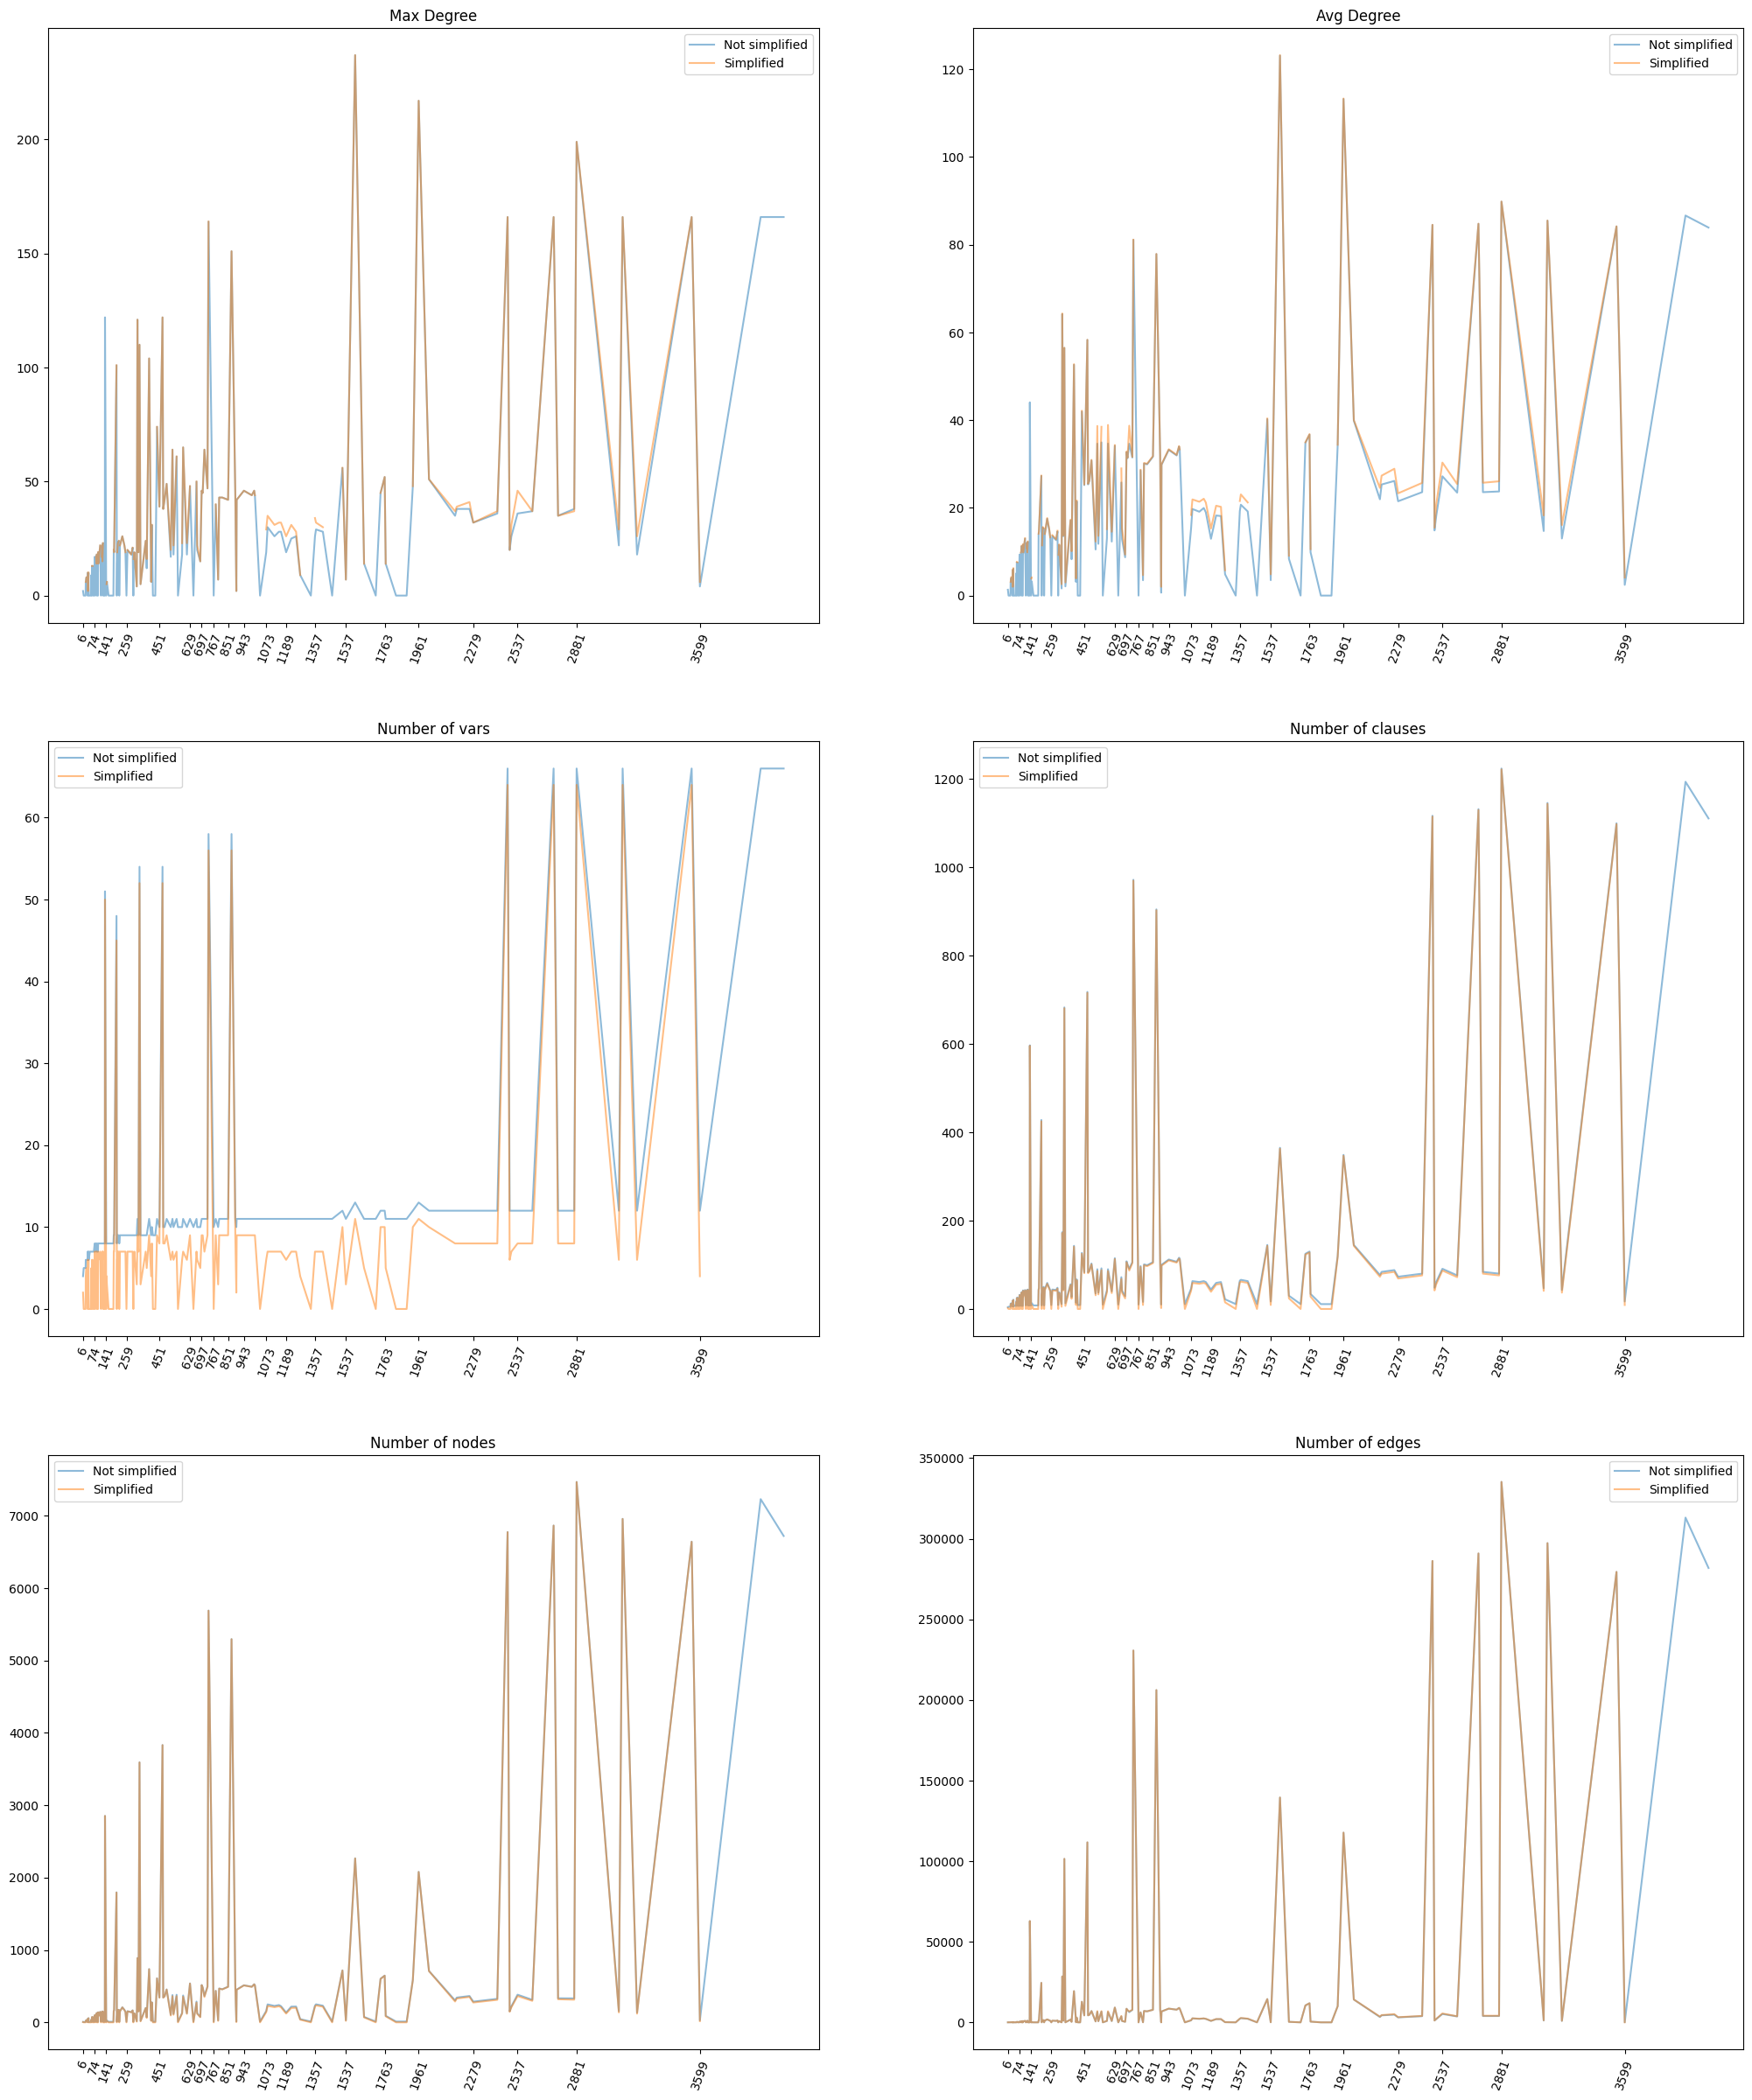

In [24]:
fig, axes = plt.subplots( 3, 2, figsize=(25, 30) )

list_ticks = [N[i] for i in range(0, int(len(N)/2), 20)] + [N[i] for i in range(int(len(N)/2)+10, len(N), 5)]
list_ticks_labels = [str(N[i]) for i in range(0, int(len(N)/2), 20)] + [str(N[i]) for i in range(int(len(N)/2)+10, len(N), 5)]

axes[0, 0].plot( N, max_, label="Not simplified", alpha=.5 )
axes[0, 0].plot( N_simpli, max__simpli, label="Simplified", alpha=.5 )
axes[0, 0].set_title( "Max Degree" )

axes[0, 1].plot( N, avg_, label="Not simplified", alpha=.5 )
axes[0, 1].plot( N_simpli, avg__simpli, label="Simplified", alpha=.5 )
axes[0, 1].set_title( "Avg Degree" )

axes[1, 0].plot( N, var_num, label="Not simplified", alpha=.5 )
axes[1, 0].plot( N_simpli, var_num_simpli, label="Simplified", alpha=.5 )
axes[1, 0].set_title( "Number of vars" )

axes[1, 1].plot( N, clauses_num, label="Not simplified", alpha=.5 )
axes[1, 1].plot( N_simpli, clauses_num_simpli, label="Simplified", alpha=.5 )
axes[1, 1].set_title( "Number of clauses" )

axes[2, 0].plot( N, num_nodes, label="Not simplified", alpha=.5 )
axes[2, 0].plot( N_simpli, num_nodes_simpli, label="Simplified", alpha=.5 )
axes[2, 0].set_title( "Number of nodes" )

axes[2, 1].plot( N, num_edges, label="Not simplified", alpha=.5 )
axes[2, 1].plot( N_simpli, num_edges_simpli, label="Simplified", alpha=.5 )
axes[2, 1].set_title( "Number of edges" )

for i in range(3):
  for j in range(2):
    axes[i,j].legend()
    axes[i,j].set_xticks( list_ticks, list_ticks_labels, **{"rotation": 70} ) 